In [ ]:
# Note: After you run this cell, the training and test data will be available in
# the file browser. (Click the folder icon on the left to view it)
#
# If you don't see the data after the cell completes, click the refresh button
# in the file browser (folder icon with circular arrow)

# First, let's download and unzip the data
!echo "Downloading files..."
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/training1.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/training2.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/holdout.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/mini_holdout.zip
!wget -q https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/mini_holdout_answers.csv

!echo "Unzipping files..."
!unzip -q /content/training1.zip
!unzip -q /content/training2.zip
!unzip -q /content/holdout.zip
!unzip -q /content/mini_holdout.zip

# Combine the two traning directories
!echo "Merging training data..."
!mkdir /content/training
!mv /content/training1/* /content/training
!mv /content/training2/* /content/training

# Cleanup
!echo "Cleaning up..."
!rmdir /content/training1
!rmdir /content/training2
!rm training1.zip
!rm training2.zip
!rm holdout.zip
!rm mini_holdout.zip

!echo "Data ready."

Unzipping files...
replace training1/00009/00043_00015.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: replace training2/00031/00004_00018.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
# Import libraries
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# We're using keras' ImageDataGenerator class to load our image data.
# See (https://keras.io/api/preprocessing/image/#imagedatagenerator-class) for details
#
# A couple of things to note:
# 1. We're specifying a number for the seed, so we'll always get the same shuffle and split of our images.
# 2. Class names are inferred automatically from the image subdirectory names.
# 3. We're splitting the training data into 80% training, 20% validation.


training_dir = '/content/training/'
image_size = (100, 100)

# Split up the training data images into training and validations sets
# We'll use and ImageDataGenerator to do the splits
# ImageDataGenerator can also be used to do preprocessing and agumentation on the files as can be seen with rescale

train_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.2
        )
validation_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.2
        )

train_generator = train_datagen.flow_from_directory(
        training_dir,
        target_size = image_size,
        subset="training",
        batch_size=32,
        class_mode='sparse',
        seed=42,shuffle=True)
validation_generator = validation_datagen.flow_from_directory(
        training_dir,
        target_size=image_size,
        batch_size=32,
        class_mode='sparse',
        subset="validation",
        seed=42)



In [ ]:
#these might come in handy
target_names = ['Speed_20', 'Speed_30', 'Speed_50', 'Speed_60', 'Speed_70',
               'Speed_80','Speed_Limit_Ends', 'Speed_100', 'Speed_120', 'Overtaking_Prohibited',
               'Overtakeing_Prohibited_Trucks', 'Priority', 'Priority_Road_Ahead', 'Yield', 'STOP',
               'Entry_Forbidden', 'Trucks_Forbidden', 'No_Entry(one-way traffic)', 'General Danger(!)', 'Left_Curve_Ahead',
               'Right_Curve_Ahead', 'Double_Curve', 'Poor_Surface_Ahead', 'Slippery_Surface_Ahead', 'Road_Narrows_On_Right',
               'Roadwork_Ahead', 'Traffic_Light_Ahead', 'Warning_Pedestrians', 'Warning_Children', 'Warning_Bikes',
               'Ice_Snow', 'Deer_Crossing', 'End_Previous_Limitation', 'Turning_Right_Compulsory', 'Turning_Left_Compulsory',
               'Ahead_Only', 'Straight_Or_Right_Mandatory', 'Straight_Or_Left_Mandatory', 'Passing_Right_Compulsory', 'Passing_Left_Compulsory',
               'Roundabout', 'End_Overtaking_Prohibition', 'End_Overtaking_Prohibition_Trucks']

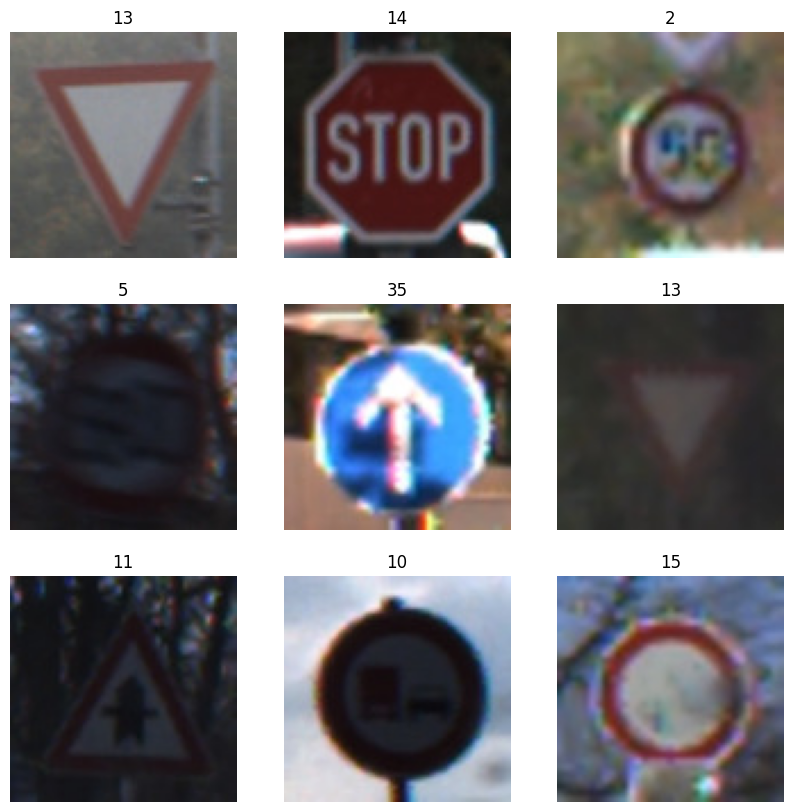

In [17]:
# View 9 images and their class labels
plt.figure(figsize=(10, 10))
images, labels = next(train_generator)  # Assuming train_generator is a generator
batch_size = images.shape[0]

for i in range(min(9, batch_size)):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow((images[i] * 255).astype("uint8"))
    plt.title(int(labels[i]))
    plt.axis("off")

plt.show()

In [ ]:
# Build a model...
model = keras.Sequential([
    layers.Input(shape=(100, 100, 3)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(43, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

In [ ]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10,
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)]
)

In [ ]:
model.save("roadsigns_model.keras")

In [ ]:
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.xlabel("epoch"); plt.legend(); plt.show()

In [ ]:
eval_datagen = ImageDataGenerator(rescale=1./255, validation_split=.2)
eval_generator = eval_datagen.flow_from_directory(
    training_dir, target_size=image_size, batch_size=32,
    class_mode='sparse', subset="validation", shuffle=False)

probs = model.predict(eval_generator)
preds = np.argmax(probs, axis=1)
y_true = eval_generator.classes

print(classification_report(y_true, preds))

In [ ]:
cm = confusion_matrix(y_true, preds)

def top_confusions(cls, k=3):
    row = cm[cls].copy()
    row[cls] = 0
    idx = np.argsort(row)[::-1][:k]
    return [(int(i), int(row[i])) for i in idx if row[i] > 0]

for c in [32, 20, 29, 30]:
    print(c, "被误认为 (类别, 张数):", top_confusions(c))

In [ ]:
test_dir = '/content/'
test_datagen = ImageDataGenerator(rescale=1./255)

mini_generator = test_datagen.flow_from_directory(
    test_dir, classes=['mini_holdout'], target_size=image_size,
    class_mode='sparse', shuffle=False)

mini_probs = model.predict(mini_generator)
mini_preds = [np.argmax(p) for p in mini_probs]

In [ ]:
answers = pd.read_csv("/content/mini_holdout_answers.csv")

pred_df = pd.DataFrame({
    "Filename": [f.split("/")[-1] for f in mini_generator.filenames],
    "Pred": mini_preds
})

merged = answers.merge(pred_df, on="Filename")
print("图片数:", len(merged))
print("mini holdout 准确率:", accuracy_score(merged["ClassId"], merged["Pred"]))
print(classification_report(merged["ClassId"], merged["Pred"], zero_division=0))

In [ ]:
merged["Correct"] = merged["ClassId"] == merged["Pred"]
wrong_rows = merged[~merged["Correct"]].sort_values("ClassId")
print(wrong_rows)

In [ ]:
plt.figure(figsize=(14, 8))
for i, (_, r) in enumerate(wrong_rows.iterrows()):
    img = plt.imread(f"/content/mini_holdout/{r['Filename']}")
    plt.subplot(3, 5, i + 1)
    plt.imshow(img)
    plt.title(f"true {r['ClassId']} / pred {r['Pred']}", fontsize=9)
    plt.axis("off")
plt.show()

In [ ]:
holdout_generator = test_datagen.flow_from_directory(
    test_dir, classes=['holdout'], target_size=image_size,
    class_mode='sparse', shuffle=False)

holdout_probs = model.predict(holdout_generator)
holdout_preds = [np.argmax(p) for p in holdout_probs]
print(len(holdout_preds))

In [ ]:
submission = pd.DataFrame({
    "Filename": [f.split("/")[-1] for f in holdout_generator.filenames],
    "ClassId": holdout_preds
})
submission.to_csv("predictions.csv", index=False)
print(submission.head())

In [ ]:
def stretch_contrast(img):
    lo, hi = np.percentile(img, 1), np.percentile(img, 99)
    img = (img - lo) / max(hi - lo, 1e-6)
    return np.clip(img, 0, 1) * 255.0

train_datagen2 = ImageDataGenerator(
    preprocessing_function=stretch_contrast, rescale=1./255,
    validation_split=.2,
    rotation_range=10, zoom_range=0.1,
    width_shift_range=0.1, height_shift_range=0.1)

val_datagen2 = ImageDataGenerator(
    preprocessing_function=stretch_contrast, rescale=1./255,
    validation_split=.2)

train_generator2 = train_datagen2.flow_from_directory(
    training_dir, target_size=image_size, subset="training",
    batch_size=32, class_mode='sparse', seed=42, shuffle=True)

validation_generator2 = val_datagen2.flow_from_directory(
    training_dir, target_size=image_size, subset="validation",
    batch_size=32, class_mode='sparse', seed=42, shuffle=False)

In [ ]:
model2 = keras.Sequential([
    layers.Input(shape=(100, 100, 3)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(43, activation="softmax"),
])
model2.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])

history2 = model2.fit(
    train_generator2, validation_data=validation_generator2, epochs=10,
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])

model2.save("roadsigns_model_v2.keras")

In [ ]:
probs2 = model2.predict(validation_generator2)
preds2 = np.argmax(probs2, axis=1)
print(classification_report(validation_generator2.classes, preds2))

test_datagen2 = ImageDataGenerator(preprocessing_function=stretch_contrast, rescale=1./255)
mini_generator2 = test_datagen2.flow_from_directory(
    test_dir, classes=['mini_holdout'], target_size=image_size,
    class_mode='sparse', shuffle=False)

mini_preds2 = np.argmax(model2.predict(mini_generator2), axis=1)
pred_df2 = pd.DataFrame({
    "Filename": [f.split("/")[-1] for f in mini_generator2.filenames],
    "Pred": mini_preds2})
merged2 = answers.merge(pred_df2, on="Filename")
print("v2 mini holdout 准确率:", accuracy_score(merged2["ClassId"], merged2["Pred"]))